[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ichristov/intermediate-fluid-mechanics/blob/main/extras/Burgers_vortex.ipynb)


# LEARNING OBJECTIVE

After exploring this notebook, you will be able to explain how "straining" a vortex along its axis stops the viscous decay of the ideal vortex (intensification of vorticity by stretching balances its viscous diffusion), using the "[Burgers vortex](https://en.wikipedia.org/wiki/Burgers_vortex)" solution of the incompressible Navier&ndash;Stokes equations.

# PRELIMINARIES

[run the next cell to setup Python environment customizations and load packages]

In [158]:
# interactive plots setup
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

# sympy setup
import sympy as sp
sp.init_printing()
from sympy.vector import *

# plotting customizations
from matplotlib import colormaps, animation, rc
from matplotlib import pyplot as plt
size=16
params = {'legend.fontsize': 'large',
#          'figure.figsize': (20,8),
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25}
plt.rcParams.update(params)
%matplotlib inline

# numerics
import numpy as np
from scipy.optimize import fsolve
import scipy.integrate as spint

# for Colab only: to save plots as files and download them
#from google.colab import files

## Credit

Initial version written by [Ivan C. Christov](http://christov.tmnt-lab.org), Purdue University.

# "STRAINING" AN IDEAL VORTEX

## Burgers vortex

In the [decay of an ideal vortex](../decay_ideal_vortex.ipynb), the Lamb&ndash;Oseen vortex spreads out forever by viscous diffusion. [Burgers (1948)](https://doi.org/10.1016/S0065-2156%2808%2970100-5) showed that a radial inflow toward the axis, which must escape along the axis, holds the vortex core at a steady size.

According to Section 11.10 of _Incompressible Flow_ [(Panton, 2013)](https://doi.org/10.1002/9781118713075), the velocity field of this _Burgers vortex_ is
$$
    v_r = -ar,\qquad v_\theta = \frac{\Gamma}{2\pi r}\left[1 - \exp\left(-\frac{ar^2}{2\nu}\right)\right],\qquad v_z = 2az,
$$
where the constant $a>0$ is the _strain rate_. Conservation of mass ties $v_z$ to $v_r$: given $v_r = -ar$, the axisymmetric continuity equation,
$$
    \frac{1}{r}\frac{\partial}{\partial r}(r v_r) + 0 + \frac{\partial v_z}{\partial z} = 0,
$$
gives $\partial_z v_z = 2a$, so $v_z = 2az$ (taking $v_z = 0$ on the plane $z = 0$). So, the same constant $a$ sets both the inflow and the outflow.

The inflow carries vorticity toward the axis, and the outflow stretches the spinning fluid along the axis, which makes it spin faster. Meanwhile, viscosity spreads the vorticity outward. In the Burgers vortex, these two effects balance.

Since $v_r \to -\infty$ as $r\to\infty$, this solution only describes the flow near the vortex core.

As for the ideal vortex, we can check that this flow is incompressible, $\nabla\cdot\underline{v}=0$, and compute its vorticity, $\underline{\omega} = \nabla \times \underline{v}$, using SymPy's [`vector`](https://docs.sympy.org/latest/modules/vector/index.html) module:

In [159]:
# create a cylindrical coordinate system for us to define vectors in
c = CoordSys3D('c')
cp = c.create_new('cp', transformation='cylindrical',
                  vector_names=("r", "th", "z"),
                  variable_names=("R", "Th", "Z"))

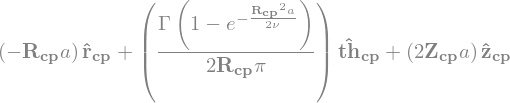

In [160]:
# the Burgers vortex' velocity
Gamma, a, nu = sp.symbols('Gamma a nu', positive=True)
v = (-a*cp.R*cp.r
     + Gamma/(2*sp.pi*cp.R)*(1 - sp.exp(-a*cp.R**2/(2*nu)))*cp.th
     + 2*a*cp.Z*cp.z)
display(v)

In [161]:
# divergence of v
divergence(v).simplify()

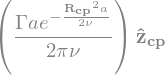

In [162]:
# curl of v
curl(v).simplify()

So, the vorticity vector $\underline{\omega}$ points along the axis:
$$
    \underline{\omega} = \omega_z \underline{e}_z 
    \quad\text{with}\quad
    \omega_z = \frac{\Gamma a}{2\pi \nu} \exp\left(-\frac{ar^2}{2\nu}\right).
$$

Unlike the vorticity of the Lamb&ndash;Oseen vortex, this vorticity does not decay in $t$, and in particular it has a finite value at $r=0$! Why? The vorticity equation, found by taking the curl of the iNS (Panton, Eq. 13.3.5), is
$$
    \frac{\partial\underline{\omega}}{\partial t} + (\underline{v}\cdot\nabla)\underline{\omega} = (\underline{\omega}\cdot\nabla)\underline{v} + \nu\nabla^2\underline{\omega}.
$$
The first term on the right, $(\underline{\omega}\cdot\nabla)\underline{v}$, is the _vorticity intensification_ (often called "vortex stretching") term (Panton, Sect. 13.5). For the Lamb&ndash;Oseen vortex, this term is zero, because $\underline{\omega} = \omega_z\underline{e}_z$ and $v_z = 0$. For the Burgers vortex, the outflow $v_z = 2az$ stretches fluid elements along the direction of $\underline{\omega}$, so this term is $(\omega_z\partial_z v_z)\,\underline{e}_z = 2a\omega_z\underline{e}_z$.

Let us compute each term with SymPy (Panton, Problem 13.4):

In [163]:
# vorticity of the Burgers vortex
omega = curl(v).simplify()

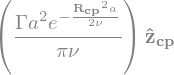

In [164]:
# vortex stretching, (omega dot grad) v
stretching = directional_derivative(v, omega).simplify()
stretching

In [165]:
# for comparison, the stretching term of the Lamb-Oseen vortex is zero
t = sp.symbols('t', positive=True)
v_LO = Gamma/(2*sp.pi*cp.R)*(1 - sp.exp(-cp.R**2/(4*nu*t)))*cp.th
directional_derivative(v_LO, curl(v_LO)).simplify()

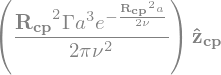

In [166]:
# advection of vorticity, (v dot grad) omega
advection = directional_derivative(omega, v).simplify()
advection

The vorticity field is divergence-free, as the divergence of a curl always is:

In [167]:
# divergence of omega
divergence(omega).simplify()

So, we can compute the viscous term as $\nu\nabla^2\underline{\omega} = -\nu\nabla\times(\nabla\times\underline{\omega})$:

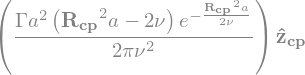

In [168]:
# viscous diffusion of vorticity, nu * laplacian(omega)
diffusion = (-nu*curl(curl(omega))).simplify()
diffusion

Now, put it together. The vorticity is steady, $\partial_t\underline{\omega} = \underline{0}$, so the vorticity equation reduces to
$$
    (\underline{v}\cdot\nabla)\underline{\omega} - (\underline{\omega}\cdot\nabla)\underline{v} - \nu\nabla^2\underline{\omega} = 0,
$$
which SymPy confirms:

In [169]:
# the vorticity is steady, so advection = stretching + diffusion
(advection - stretching - diffusion).simplify()

The stretching term, $2a\omega_z\underline{e}_z$, is positive everywhere: a fluid element stretched along its spin axis gets thinner and spins faster, like a figure skater pulling in their arms. On the axis, where $v_r = 0$ and there is no advection, stretching balances the viscous diffusion of vorticity away from the axis. The Lamb&ndash;Oseen vortex has no stretching, so nothing stops its vorticity from diffusing away.

## Self-similar solution

To see how the Burgers vortex forms, we take the ideal vortex as the initial condition and switch on the inflow at $t=0$. Adding the time derivative to the $\theta$-momentum equation (Panton, Sect. 11.10), the IBVP is
\begin{align*}
    \frac{\partial v_\theta}{\partial t} - ar\frac{\partial v_\theta}{\partial r} - a v_\theta &= \nu \frac{\partial}{\partial r}\left[\frac{1}{r}\frac{\partial}{\partial r}\left(r v_\theta\right)\right],\\
    v_\theta(r, t = 0) &= \frac{\Gamma}{2\pi r},\\
    v_\theta(r \to \infty, t \ge 0) &\sim \frac{\Gamma}{2\pi r},\\
    v_\theta(r = 0, t > 0) &= 0.
\end{align*}
For $a=0$, this is the IBVP for the Lamb&ndash;Oseen vortex.

The solution [(Rott, 1958)](https://doi.org/10.1007/BF02424773) has the same form as the Lamb&ndash;Oseen vortex,
$$
    v_\theta(r,t) = \frac{\Gamma}{2\pi r}f(\eta),\qquad f(\eta) = 1 - \exp\left(-\frac{\eta^2}{4}\right),\qquad \eta = \frac{r}{\sqrt{\nu\,\tau(t)}},
$$
but the time $t$ is replaced by the _effective time_
$$
    \tau(t) = \frac{1 - e^{-2at}}{2a}.
$$
At early times, $at \ll 1$, we have $\tau \approx t$, and the vortex decays like the Lamb&ndash;Oseen vortex. At late times, $at \gg 1$, we have $\tau \to 1/(2a)$ and $\eta \to r/\sqrt{\nu/2a}$, which is the steady Burgers vortex, with $\eta$ as defined by Panton.

We can check with SymPy that this solution satisfies the PDE:

In [170]:
# the unsteady solution
r, t = sp.symbols('r t', positive=True)
tau = (1 - sp.exp(-2*a*t))/(2*a)
v_theta = Gamma/(2*sp.pi*r)*(1 - sp.exp(-r**2/(4*nu*tau)))

# the two sides of the PDE, which should be equal
lhs = v_theta.diff(t) - a*r*v_theta.diff(r) - a*v_theta
rhs = nu*((r*v_theta).diff(r)/r).diff(r)
sp.simplify(lhs - rhs)

and that $\tau \to t$ as $a\to 0$, and $\tau \to 1/(2a)$ as $t\to\infty$:

In [171]:
sp.limit(tau, a, 0)

In [172]:
sp.limit(tau, t, sp.oo)

The vorticity is then
$$
    \omega_z = \frac{\Gamma}{4\pi \nu \tau} \exp\left(-\frac{r^2}{4\nu \tau}\right),
$$
which tends to the steady vorticity of the Burgers vortex, found above, as $t\to\infty$.

In [173]:
# define the self-similar solution as a function
def f_selfsimilar(eta):
    return 1 - np.exp(-eta**2/4)

# define the effective time, tau(t), as a function
def tau_eff(t, a):
    return (1 - np.exp(-2*a*t))/(2*a)

# define the corresponding vorticity, omega_z(r,tau), as a function
def omega_z(r, tau, Gamma, nu):
    return Gamma/(4*np.pi*nu*tau)*np.exp(-r**2/(4*nu*tau))

## Visualization

### Azimuthal velocity

In [174]:
# kinematic viscosity of water
nu_num = 1  # mm^2/s, so time will be in s and distance in mm for the plots below

# circulation
Gm = 1  # also in mm^2/s

# strain rate
a_num = 2  # 1/s

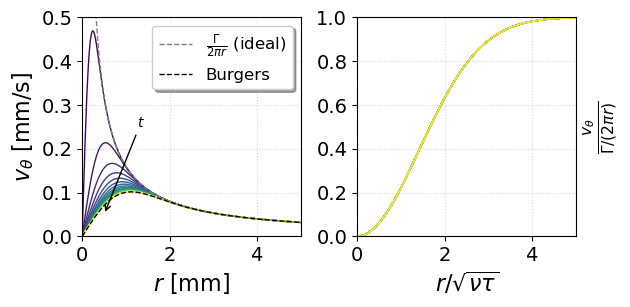

In [175]:
# define vertical extent of the eta plot and grid
etamax = 5.0
eta = np.linspace(0, etamax, 250)

# define vertical extent of the r plot and grid (avoiding r=0 singularity)
rmax = 5.0
r = np.linspace(1e-6, rmax, 250)

# sequential colormap with gradient that looks nice, also try 'cool' or 'summer'
# https://matplotlib.org/stable/users/explain/colors/colormaps.html#sequential
cmap = colormaps['viridis']

# set up the figure and axis
fig, ax = plt.subplots(1, 2, tight_layout=True)
ax[0].set_xlabel('$r$ [mm]')
ax[0].set_xlim(0, rmax)
ax[0].set_ylabel(r'$v_\theta$ [mm/s]')
ax[0].set_ylim(0, 0.5)
ax[0].set_aspect(1.0/ax[0].get_data_ratio(), adjustable='box')

ax[1].set_xlabel(r'$r/\sqrt{\nu \tau}$')
ax[1].set_xlim(0, etamax)
ax[1].set_ylabel(r'$\frac{v_\theta}{\Gamma/(2\pi r)}$')
ax[1].set_ylim(0, 1)
ax[1].set_aspect(1.0/ax[1].get_data_ratio(), adjustable='box')
ax[1].yaxis.set_label_position('right')

tmin = 0.012
tmax = 1.0
for t_num in np.linspace(tmin, tmax, 20):
    tau_num = tau_eff(t_num, a_num)
    vth = Gm/(2*np.pi*r)*f_selfsimilar(r/np.sqrt(nu_num*tau_num))
    tcol = cmap(t_num/tmax)  # argument from 0 to 1
    ax[0].plot(r, vth, linewidth=1, color=tcol)
    ax[1].plot(r/np.sqrt(nu_num*tau_num), vth/(Gm/(2*np.pi*r)), linewidth=1, color=tcol)

ax[0].plot(r, Gm/(2*np.pi*r), color='gray', linewidth=1, linestyle='dashed',
           label=r'$\frac{\Gamma}{2\pi r}$ (ideal)')
ax[0].plot(r, Gm/(2*np.pi*r)*f_selfsimilar(r/np.sqrt(nu_num/(2*a_num))),
           color='black', linewidth=1, linestyle='dashed', label='Burgers')
ax[0].legend(framealpha=1, shadow=True)

ax[1].grid(alpha=0.5, linestyle='dotted')
ax[0].grid(alpha=0.5, linestyle='dotted')

ax[0].annotate('$t$', xy=(0.5, 0.05), xytext=(1.25, 0.25),
               arrowprops=dict(arrowstyle="->"));

The curves stop changing once $at \gtrsim 1$, when they reach the steady Burgers vortex (black dashed curve). In the self-similar variable $\eta = r/\sqrt{\nu\tau}$, all curves collapse onto $f(\eta)$, just as for the Lamb&ndash;Oseen vortex.

We can also illustrate how the solution evolves from the ideal vortex to the Burgers vortex as an animation.

In [176]:
# define vertical extent of the eta plot and grid
etamax = 5.0
eta = np.linspace(0, etamax, 500)

# define vertical extent of the r plot and grid (avoiding r=0 singularity)
rmax = 5.0
r = np.linspace(1e-6, rmax, 500)

# sequential colormap with gradient that looks nice, also try 'cool' or 'summer'
# https://matplotlib.org/stable/users/explain/colors/colormaps.html#sequential
cmap = colormaps['viridis']

# set up the figure and axis
fig, ax = plt.subplots(1, 2, tight_layout=True)
ax[0].set_xlabel('$r$ [mm]')
ax[0].set_xlim(0, rmax)
ax[0].set_ylabel(r'$v_\theta$ [mm/s]')
ax[0].set_ylim(0, 0.3)
ax[0].set_aspect(1.0/ax[0].get_data_ratio(), adjustable='box')

ax[1].set_xlabel(r'$r/\sqrt{\nu \tau}$')
ax[1].set_xlim(0, etamax)
ax[1].set_ylabel(r'$\frac{v_\theta}{\Gamma/(2\pi r)}$')
ax[1].set_ylim(0, 1)
ax[1].set_aspect(1.0/ax[1].get_data_ratio(), adjustable='box')
ax[1].yaxis.set_label_position('right')

ax[1].grid(alpha=0.5, linestyle='dotted')
ax[0].grid(alpha=0.5, linestyle='dotted')
plt.close()

# initialize plot and quiver objects with some dummy data (replaced in animation)
ax[0].plot(r, 0*r, linewidth=1, color=cmap(0))
ax[1].plot(eta, 0*eta, linewidth=1, color=cmap(0))

# add envelope of all curves, and the steady Burgers vortex
ax[0].plot(r, Gm/(2*np.pi*r),
           color='gray', linewidth=1, linestyle='dashed',
           label=r'$\frac{\Gamma}{2\pi r}$')
ax[0].plot(r, Gm/(2*np.pi*r)*f_selfsimilar(r/np.sqrt(nu_num/(2*a_num))),
           color='black', linewidth=1, linestyle='dashed', label='Burgers')
ax[0].legend(framealpha=1, shadow=True)

time_label = ax[0].annotate('$t=0$', xy=(0.675*rmax, 0.45))

# number of animation frames
numframes = 50
tmin = 0.05
tmax = 1.5

# animation function called sequentially by 'FuncAnimation' below
def animate(t):
    # the t passed is actually the frame counter, not time
    # so it should be rescaled to get actual time as % of the frames
    # also shift it slightly so we don't divide by 0
    tt = tmin + t/numframes * tmax

    tau_num = tau_eff(tt, a_num)
    vth = Gm/(2*np.pi*r)*f_selfsimilar(r/np.sqrt(nu_num*tau_num))
    randcol = cmap(tt/tmax)  # argument from 0 to 1
    ax[0].plot(r, vth, linewidth=1, color=randcol)
    ax[1].plot(r/np.sqrt(nu_num*tau_num), vth/(Gm/(2*np.pi*r)),
               linewidth=1, color=randcol)

    # dynamic time label in the corner
    time_label.set_text(f'$t={tt:.2f}$ s')

    return fig,


anim = animation.FuncAnimation(fig, animate,
                               frames=numframes, interval=300, blit=True, repeat=False)

In [177]:
# this is necessary to get the animation to work on Google's Colab
rc('animation', html='jshtml')
display(anim)

In [178]:
# To save the animation, use something like
# anim.save(f"burgers_vel_movie.mp4")

# or
# writer = animation.FFMpegWriter(fps=15, metadata=dict(artist='Me'), bitrate=1800)
# anim.save(f"burgers_vel_movie.mp4", writer=writer)

### Viscous region

As for the Lamb&ndash;Oseen vortex, let us calculate the value of $\eta=\eta_{99\%}$ such that $\frac{v_\theta}{\Gamma/(2\pi r)} = 0.99$ (equivalently, $\eta$ such that $v_\theta = 0.99 \frac{\Gamma}{2\pi r}$).

In [179]:
def eq_func(eta99pc):
    # define a function f(eta) - 0.99, which = 0 for the value
    # of \eta = \eta_{99\%} that we seek as a solution;
    return f_selfsimilar(eta99pc) - 0.99

eta99pc_initial_guess = 1
eta99pcsol = fsolve(eq_func, eta99pc_initial_guess)
eta99pcsol[0]

Since $f(\eta)$ is the same function as for the Lamb&ndash;Oseen vortex, we get the same $\eta_{99\%} \approx 4.29$. The radius $r=\delta$ of the viscous region is then
$$
    \delta \approx 4.29 \sqrt{\nu \tau(t)} \quad\to\quad 4.29\sqrt{\frac{\nu}{2a}} \quad\text{as } t\to\infty.
$$
The viscous region of the Lamb&ndash;Oseen vortex grows like $\sqrt{\nu t}$ forever, but the inflow stops the viscous region of the Burgers vortex from growing. A larger strain rate $a$ gives a thinner vortex core.

Let's plot $\delta(t)$ together with its two limits: the Lamb&ndash;Oseen growth, $\delta \approx \eta_{99\%}\sqrt{\nu t}$ for $at \ll 1$, and the steady Burgers core, $\delta \to \delta_\infty = \eta_{99\%}\sqrt{\nu/2a}$ for $at \gg 1$. Scaled by $\delta_\infty$, the curve, $\delta/\delta_\infty = \sqrt{1 - e^{-2at}}$, is the same for every $a$ and $\nu$.

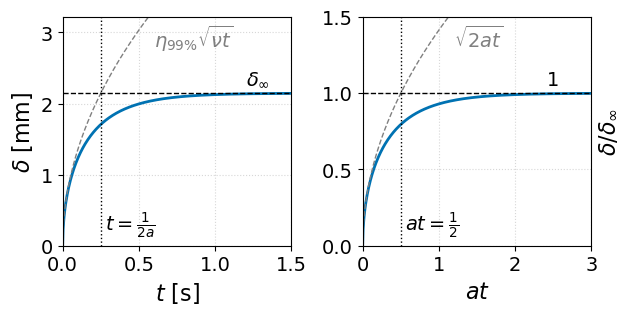

In [180]:
# time grid, and the radius of the viscous region
tmax = 1.5
t_num = np.linspace(0, tmax, 500)
delta_t = eta99pcsol[0]*np.sqrt(nu_num*tau_eff(t_num, a_num))

# its two limits, and the time at which they cross
delta_LO = eta99pcsol[0]*np.sqrt(nu_num*t_num)
delta_inf = eta99pcsol[0]*np.sqrt(nu_num/(2*a_num))
t_cross = 1/(2*a_num)

# set up the figure and axis
fig, ax = plt.subplots(1, 2, tight_layout=True)
ax[0].set_xlabel('$t$ [s]')
ax[0].set_xlim(0, tmax)
ax[0].set_ylabel(r'$\delta$ [mm]')
ax[0].set_ylim(0, 1.5*delta_inf)
ax[0].set_aspect(1.0/ax[0].get_data_ratio(), adjustable='box')

ax[1].set_xlabel('$at$')
ax[1].set_xlim(0, a_num*tmax)
ax[1].set_ylabel(r'$\delta/\delta_\infty$')
ax[1].set_ylim(0, 1.5)
ax[1].set_aspect(1.0/ax[1].get_data_ratio(), adjustable='box')
ax[1].yaxis.set_label_position('right')

# left: dimensional
ax[0].plot(t_num, delta_t, linewidth=2, color='#0072B2')
ax[0].plot(t_num, delta_LO, linewidth=1, color='gray', linestyle='dashed')
ax[0].axhline(delta_inf, linewidth=1, color='black', linestyle='dashed')
ax[0].axvline(t_cross, linewidth=1, color='black', linestyle='dotted')
ax[0].text(0.4*tmax, 1.3*delta_inf, r'$\eta_{99\%}\sqrt{\nu t}$', 
           color='gray', fontsize=size*0.875)
ax[0].text(0.8*tmax, 1.05*delta_inf, r'$\delta_\infty$', fontsize=size*0.875)
ax[0].text(1.1*t_cross, 0.1*delta_inf, r'$t = \frac{1}{2a}$', fontsize=size*0.875)

# right: dimensionless, the same for every a and nu
ax[1].plot(a_num*t_num, delta_t/delta_inf, linewidth=2, color='#0072B2')
ax[1].plot(a_num*t_num, np.sqrt(2*a_num*t_num), 
           linewidth=1, color='gray', linestyle='dashed')
ax[1].axhline(1, linewidth=1, color='black', linestyle='dashed')
ax[1].axvline(1/2, linewidth=1, color='black', linestyle='dotted')
ax[1].text(0.4*a_num*tmax, 1.3, r'$\sqrt{2at}$', color='gray', fontsize=size*0.875)
ax[1].text(0.8*a_num*tmax, 1.05, '$1$', fontsize=size*0.875)
ax[1].text(1.1*1/2, 0.1, r'$at = \frac{1}{2}$', fontsize=size*0.875)

ax[1].grid(alpha=0.5, linestyle='dotted')
ax[0].grid(alpha=0.5, linestyle='dotted')

# if you want to save the figure to a file
# fig.savefig("burgers_delta.pdf") # bbox_inches='tight'


The two limits cross at $t = 1/(2a)$, which estimates how long the Burgers vortex takes to form. Before then, the viscous region grows by diffusion, as for the Lamb&ndash;Oseen vortex. After that, the inflow holds it at a steady size.

### Vorticity

Let's plot the vorticity component $\omega_z$ as a function of $r$, and show the viscous region in the self-similar plot.

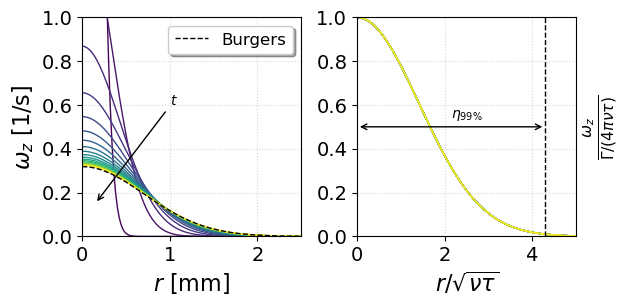

In [181]:
# define vertical extent of the eta plot and grid
etamax = 5.0
eta = np.linspace(0, etamax, 250)

# define vertical extent of the t plot and grid
rmax = 5.0
r = np.linspace(0, rmax, 250)

# set up the figure and axis
fig, ax = plt.subplots(1, 2, tight_layout=True)
ax[0].set_xlabel('$r$ [mm]')
ax[0].set_xlim(0, rmax/2)
ax[0].set_ylabel(r'$\omega_z$ [1/s]')
ax[0].set_ylim(0, 1)
ax[0].set_aspect(1.0/ax[0].get_data_ratio(), adjustable='box')

ax[1].set_xlabel(r'$r/\sqrt{\nu \tau}$')
ax[1].set_xlim(0, etamax)
ax[1].set_ylabel(r'$\frac{\omega_z}{\Gamma/(4\pi \nu \tau)}$')
ax[1].set_ylim(0, 1)
ax[1].set_aspect(1.0/ax[1].get_data_ratio(), adjustable='box')
ax[1].yaxis.set_label_position('right')

tmin = 0.01
tmax = 1.0
for t_num in np.linspace(tmin, tmax, 20):
    tau_num = tau_eff(t_num, a_num)
    wz = omega_z(r, tau_num, Gm, nu_num)
    tcol = cmap(t_num/tmax)  # argument from 0 to 1
    ax[0].plot(r, wz, linewidth=1, color=tcol)
    ax[1].plot(r/np.sqrt(nu_num*tau_num), wz/(Gm/(4*np.pi*nu_num*tau_num)),
               linewidth=1, color=tcol)

# the steady Burgers vortex
ax[0].plot(r, Gm*a_num/(2*np.pi*nu_num)*np.exp(-a_num*r**2/(2*nu_num)),
           color='black', linewidth=1, linestyle='dashed', label='Burgers')
ax[0].legend(framealpha=1, shadow=True)

ax[1].grid(alpha=0.5, linestyle='dotted')
ax[0].grid(alpha=0.5, linestyle='dotted')

ax[0].annotate('$t$', xy=(0.15, 0.15),
               xytext=(1.0, 0.6), arrowprops=dict(arrowstyle="->"))

ax[1].plot(eta99pcsol[0]*np.ones_like(np.linspace(0, rmax)),
           np.linspace(0, rmax),
           linewidth=1, color='black', linestyle='dashed')

# add nice arrows
ax[1].text(eta99pcsol[0]/2, 0.54, r'$\eta_{99\%}$')
ax[1].annotate("", (0, 0.5), (eta99pcsol[0], 0.5),
               arrowprops={'arrowstyle': '<->'});

As for the Lamb&ndash;Oseen vortex, the vorticity at the origin diffuses radially outward. Now, however, the inflow carries vorticity back toward the axis, and the vorticity profile stops changing once the two effects balance.

The vortex core, in which all the vorticity is concentrated, is $r \le \delta = \eta_{99\%} \sqrt{\nu\,\tau}$ as above.

### Vector field

In [182]:
# range
xmax = 3
ymax = 3

# grid, picking an even num to avoid (0,0) being in the plotting points
# obviously, "bad things" happen at the origin when we go to polar coords
x, y = np.meshgrid(np.linspace(-xmax, xmax, num=36),
                   np.linspace(-ymax, ymax, num=36))

# convert (x,y) to (r,th) for plotting in polar coordinates
# note: arctan2(y,x) computes arctangent(y/x) taking into account the
# signs of x and y, which is important for these problems.
# if you use atan(y/x), you'd get funny results due to the 'branch cut' of atan.
r = np.sqrt(x**2 + y**2)
th = np.arctan2(y, x)

In [183]:
# a stronger vortex than above, so the swirl is visible next to the inflow
Gm_strong = 100  # mm^2/s

# set up the figure and axis
fig, ax = plt.subplots(tight_layout=True)
ax.set_ylabel('$y$ [mm]')
ax.set_xlabel('$x$ [mm]')
ax.set_aspect('equal')

# initialize plot and quiver objects with the ideal vortex solution

# the polar velocity field
vr = -a_num*r
vth = Gm_strong/(2*np.pi*r)

# transform polar velocities to Cartesian ones for plotting
vx = vr*np.cos(th) - vth*np.sin(th)
vy = vr*np.sin(th) + vth*np.cos(th)

# skip every other row and column to reduce number of arrows
quiv = ax.quiver(x[::2, ::2], y[::2, ::2], vx[::2, ::2], vy[::2, ::2],
                 scale=20, scale_units='xy', color='blue')

# add a single viscous-region patch and use it in the legend
tmin = 0.012
visc_disk = plt.Circle(
    (0, 0),
    eta99pcsol[0]*np.sqrt(nu_num*tau_eff(tmin, a_num)),
    facecolor='coral',
    edgecolor='none',
    alpha=0.4,
    zorder=0,
    label='viscous region'
)
ax.add_patch(visc_disk)
ax.legend(handles=[visc_disk], loc='lower right', bbox_to_anchor=(1.3, 0.),
          framealpha=1, shadow=True)

# if you want to save the thumbnail to a file
# fig.savefig("burgers_quiver_thumb.pdf") # bbox_inches='tight'

plt.close()

# number of animation frames
numframes = 50
tmax = 1.5

time_label = ax.annotate('$t=0$', xy=(0.8*xmax, 0.9*ymax),
                         bbox=dict(boxstyle="round", facecolor="white"))

# animation function called sequentially by `FuncAnimation' below
def animate(t):
    # the t passed is actually the frame counter, not time
    # so it should be rescaled to get actual time as % of the frames
    # also shift it slightly so we don't divide by 0
    tt = tmin + t/numframes * tmax
    tau_num = tau_eff(tt, a_num)

    # the polar velocity field
    vr = -a_num*r
    vth = Gm_strong/(2*np.pi*r)*f_selfsimilar(r/np.sqrt(nu_num*tau_num))

    # transform polar velocities to Cartesian ones for plotting
    vx = vr*np.cos(th) - vth*np.sin(th)
    vy = vr*np.sin(th) + vth*np.cos(th)

    # update the arrows
    quiv.set_UVC(vx[::2, ::2], vy[::2, ::2])

    # dynamic time label in the corner
    time_label.set_text(f'$t={tt:.2f}$ s')

    # update viscous-region radius in time
    visc_disk.set_radius(eta99pcsol[0] * np.sqrt(nu_num * tau_num))

    return (quiv, )


anim = animation.FuncAnimation(fig, animate,
                               frames=numframes, interval=500, blit=True)

In [184]:
# this is necessary to get the animation to work on Google's Colab
rc('animation', html='jshtml')
anim

In [185]:
# To save the animation, use something like
# anim.save(f"burgers_quiver_movie.mp4")

# or
# writer = animation.FFMpegWriter(fps=15, metadata=dict(artist='Me'), bitrate=1800)
# anim.save(f"burgers_quiver_movie.mp4", writer=writer)

The arrows spiral inward because of the inflow, $v_r = -ar$. The fluid then leaves along the axis with $v_z = 2az$, perpendicular to the plot. The arrows far from the axis are long because $v_r$ grows with $r$; this is why the Burgers vortex only describes the flow near the vortex core.

### Pathlines in 3D

For the steady Burgers vortex, $v_r = -ar$ and $v_z = 2az$ integrate exactly to the radial and axial positions of a fluid particle, $r(t) = r_0 e^{-at}$ and $z(t) = z_0 e^{2at}$. The angular position follows from $d\theta/dt = v_\theta/r$, which we integrate numerically. We keep the stronger vortex from the vector field above.

In [186]:
# times at which we track the fluid particles
times = np.linspace(0, 1.5, 1000)  # s

# all particles start at the same radius, so they share r(t) and theta(t) - theta_0
r0 = 3  # mm
r_path = r0*np.exp(-a_num*times)
vth_path = Gm_strong/(2*np.pi*r_path)*f_selfsimilar(r_path/np.sqrt(nu_num/(2*a_num)))
th_turn = spint.cumulative_trapezoid(vth_path/r_path, times, initial=0)

# starting angles and heights of three particles
th0 = np.array([0, 2*np.pi/3, 4*np.pi/3])
z0 = np.array([0.01, -0.01, 0.005])  # mm

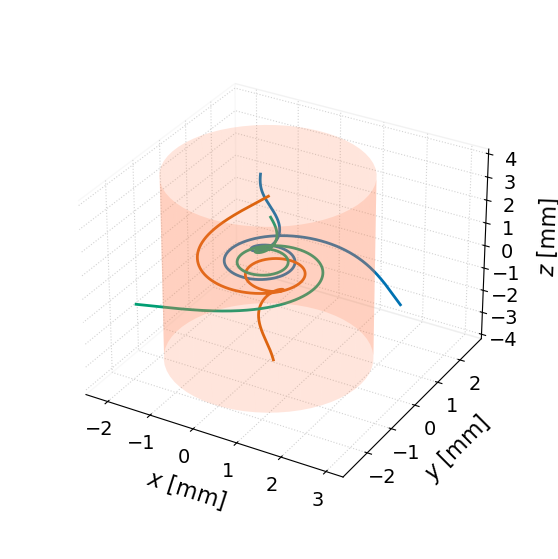

In [187]:
# set up the figure and axis
fig = plt.figure(figsize=(7, 7))
# a light, dotted grid (3D axes take their grid style from rcParams)
with plt.rc_context({'grid.color': 'lightgray', 'grid.linestyle': 'dotted'}):
    ax = fig.add_subplot(projection='3d')
ax.set_box_aspect(None, zoom=0.85)
ax.set_xlabel('$x$ [mm]', labelpad=12)
ax.set_ylabel('$y$ [mm]', labelpad=12)
ax.set_zlabel('$z$ [mm]', labelpad=12)

# remove the default gray backing panes
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

# the vortex core, r <= delta, as a see-through cylinder
th_grid, z_grid = np.meshgrid(np.linspace(0, 2*np.pi, 60), np.linspace(-4, 4, 2))
delta = eta99pcsol[0]*np.sqrt(nu_num/(2*a_num))
ax.plot_surface(delta*np.cos(th_grid), delta*np.sin(th_grid), z_grid,
                color='coral', alpha=0.2, shade=False)

# colorblind-safe colors (Okabe-Ito)
colors = ['#0072B2', '#D55E00', '#009E73']

# the pathlines
for m in range(len(th0)):
    th_path = th0[m] + th_turn
    z_path = z0[m]*np.exp(2*a_num*times)
    ax.plot(r_path*np.cos(th_path), r_path*np.sin(th_path), z_path,
            linewidth=2, color=colors[m])

# if you want to save the figure to a file
# fig.savefig("burgers_pathlines.pdf") # bbox_inches='tight'


Each fluid particle spirals in toward the vortex core (shaded), turns faster as it gets closer to the axis, and then leaves along the axis, up or down depending on the sign of $z_0$. This axial outflow is what stretches the spinning fluid along the axis.

# FURTHER EXPLORATION

On your own:
*   Recall the strain-rate tensor $S_{ij}$ from our study of flow kinematics. Compute its components for the Burgers vortex in cylindrical coordinates (see the appendix of Panton for the formulas). Which components are set by the strain rate $a$, and which by the swirl $v_\theta$?
*   Compute each term of the vorticity equation for the unsteady solution, as we did above for the steady Burgers vortex. How does the balance between the terms change as the vortex forms?
*   If the initial vortex is a Lamb&ndash;Oseen vortex of age $\tau_0$, instead of an ideal vortex, the effective time becomes $$\tau(t) = \tau_0 e^{-2at} + \frac{1 - e^{-2at}}{2a}.$$ Redo the vorticity plot with $\tau_0 > 1/(2a)$. How does the peak vorticity change in time, and why?
*   Estimate the steady core radius, $\delta \approx 4.29\sqrt{\nu/2a}$, of a vortex stretched at $a = 1$ 1/s in water ($\nu = 1$ mm<sup>2</sup>/s) and in air ($\nu = 15$ mm<sup>2</sup>/s).

# REFERENCES

J. M. Burgers, A mathematical model illustrating the theory of turbulence, in: _Advances in Applied Mechanics_, Vol. 1, Academic Press, 1948, pp. 171&ndash;199. [doi:10.1016/S0065-2156(08)70100-5](https://doi.org/10.1016/S0065-2156%2808%2970100-5)

R. L. Panton, _Incompressible Flow_, 4th ed., Wiley, 2013. [doi:10.1002/9781118713075](https://doi.org/10.1002/9781118713075)

N. Rott, On the viscous core of a line vortex, _Z. Angew. Math. Phys._ **9** (1958) 543&ndash;553. [doi:10.1007/BF02424773](https://doi.org/10.1007/BF02424773)